# Compare the dummy and logistic baselines: deduplicated Subset data

Does learning from age, sex and site improve on giving everyone the training data's malignant-image rate? This short walkthrough introduces two simple metadata models; metadata means the recorded information alongside an image.

[03_patient_fold_verification.ipynb](03_patient_fold_verification.ipynb) supplies the patient groups. [05_metadata_models.ipynb](05_metadata_models.ipynb) expands this comparison to five methods.

The saved logistic model has average precision (AP) 0.0430, versus 0.0184 (pooled); primary mean-fold AP is 0.0567 versus 0.0189 for the dummy. At a cutoff of 0.50, both leave every image unflagged. The reserved test is not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [04_dummy_logistic_baseline.ipynb](../Subset/04_dummy_logistic_baseline.ipynb).

The clean workflow's primary ranking measure is **unweighted mean outer-fold AP**. The original pooled tables and figures are retained for presentation consistency and are explicitly secondary; their values are not interchangeable with mean-fold scores.

## Context and methods

The prevalence dummy returns the malignant-image rate in its training data. Logistic regression learns weights for age, sex and site categories, combines them and produces a score between 0 and 1. Neither method reads image pixels.

A fold is a group of patients. We train on four folds and predict the fifth, five times. These out-of-fold (OOF) predictions are made without training on the scored patient's images. Category encoding is learned separately within training. Diagnosis and benign/malignant labels reveal the answer; identifiers and fold numbers are also excluded from inputs.

AP measures how well malignant images concentrate near the top of the score ranking; it is not classification accuracy. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance-level ranking. Larger values are better for both. Scores in [0,1] are probability estimates whose calibration, agreement with observed rates, still needs checking.

We show decisions at 0.50, then choose an exploratory logistic cutoff from the same OOF labels. That illustrates a trade-off but can overstate future performance. Notebook 08 later separates cutoff selection from assessment.


## Data

### 1. Load and check the patient folds

The counts below describe the same 6,706 development images used in notebook 03. We check that each patient belongs to one preserved fold and match saved clean predictions. Exact pixel-copy removal retains all 422 patients and 88 malignant patients; 158 copies were removed, leaving 6,706 images and 127 malignant images. The reserved test data is not loaded.


In [1]:
NOTEBOOK_STAGE = '04_metadata_baselines'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score,
    balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss,
    roc_auc_score, roc_curve, precision_recall_curve,
)
from melanoma_detection.metadata_evaluation import probability_metrics, decision_metrics, calibration_bins
from melanoma_detection.dedup_notebook_metadata import (
    saved_metadata, metric_table, exploratory_cutoff, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
from melanoma_detection.dedup_notebook_metadata_templates import marginal_age_profile, metadata_patient_intervals
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
PROJECT_ROOT = ROOT
train = bundle["frame"].set_index("image_name").loc[frame.image_id].reset_index()
assert np.array_equal(train.patient_id, frame.patient_id)
assert np.array_equal(train.target, frame.target)
assert np.array_equal(train.fold, frame.fold)
assert train.groupby("patient_id").fold.nunique().eq(1).all()
assert train.image_name.is_unique and len(train) == 6706
assert int(train.target.sum()) == 127
FEATURE_COLUMNS = ["sex", "age_approx", "anatom_site_general_challenge"]
FEATURES = FEATURE_COLUMNS
DATA_PATH = ROOT / "data/subset/processed/dedup_v1/dataset_manifest.json"
TRAIN_FOLDS_PATH = DATA_PATH
REPORT_DIR = ROOT / "results/dedup_v1/clean_workflow/metadata_depth" / NOTEBOOK_STAGE
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = FIGURE_DIR
TABLES = METRICS = PREDICTIONS = REPORT_DIR
plt.rcdefaults()

def binary_probability_metrics(targets, probabilities):
    values = probability_metrics(targets, probabilities)
    return {"roc_auc": values["roc_auc"], "average_precision": values["average_precision"],
            "log_loss": values["log_loss"], "brier_score": values["brier"]}

MODEL_LABELS = {"dummy": "Prevalence dummy", "logistic": "Logistic regression"}
COLORS = {"dummy": "#94A3B8", "logistic": "#2563EB"}

print(f"Manifest: {DATA_PATH.relative_to(ROOT)}")
print(f"Dataset identity: {bundle['identity']['dataset_identity']}")
print(f"Images: {len(train):,}; patients: {train.patient_id.nunique():,}")
print(f"Malignant images: {int(train.target.sum()):,} ({train.target.mean():.2%})")
print(f"Malignant patients: {train.loc[train.target.eq(1), 'patient_id'].nunique():,}")
print("Original patient folds retained; reserved test not loaded.")

ORIGINAL_EXPORT_DPI = 150


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

Manifest: data\subset\processed\dedup_v1\dataset_manifest.json
Dataset identity: 0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae9f9eb7e57825b04af1
Images: 6,706; patients: 422
Malignant images: 127 (1.89%)
Malignant patients: 88
Original patient folds retained; reserved test not loaded.


## Results

### 2. Load and verify held-out probabilities

The saved clean methods trained and predicted on exactly the same patient splits. The dummy gives one constant probability within each fold. Its five printed probabilities differ slightly because each training fold has a slightly different malignant-image rate.


In [2]:

estimators = {"dummy": "saved dummy", "logistic": "saved categorical logistic"}
oof_predictions = train[["image_name", "patient_id", "fold", "target"]].copy()
oof_predictions["dummy_probability"] = scores["dummy"]
oof_predictions["logistic_probability"] = scores["categorical_logistic"]
assert oof_predictions.filter(like="probability").notna().all().all()
print(f"Loaded verified OOF probabilities for {len(oof_predictions):,} images.")
print("Distinct dummy probabilities:")
print(np.sort(oof_predictions.dummy_probability.unique()))


Loaded verified OOF probabilities for 6,706 images.
Distinct dummy probabilities:
[0.01867258 0.01878022 0.01891386 0.01911903 0.01920925]


### 3. Compare ranking scores

Read the pooled OOF scores as the result across all held-out images. The mean fold ROC-AUC averages the five separate fold scores. They need not be identical. The added mean-fold table is primary for this clean workflow; mean-fold AP is 0.0189 for the dummy and 0.0567 for logistic regression. The following table also checks that the dummy has exactly 0.5 ROC-AUC within each fold, as expected for a constant score.


In [3]:
metric_rows = []
fold_metric_rows = []

for model_name in estimators:
    probability_column = f"{model_name}_probability"
    overall_metrics = binary_probability_metrics(
        oof_predictions["target"],
        oof_predictions[probability_column],
    )

    fold_auc_values = []
    for fold in sorted(oof_predictions["fold"].unique()):
        fold_mask = oof_predictions["fold"].eq(fold)
        fold_auc = roc_auc_score(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        fold_ap = average_precision_score(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        fold_auc_values.append(fold_auc)
        fold_metric_rows.append(
            {
                "Model": MODEL_LABELS[model_name],
                "Fold": int(fold),
                "ROC-AUC": fold_auc,
                "Average precision": fold_ap,
            }
        )

    metric_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Pooled OOF ROC-AUC": overall_metrics["roc_auc"],
            "Mean fold ROC-AUC": np.mean(fold_auc_values),
            "Average precision": overall_metrics["average_precision"],
        }
    )

metrics = pd.DataFrame(metric_rows).set_index("Model")
fold_metrics = pd.DataFrame(fold_metric_rows)

metrics.round(4)

display(metrics.round(4))
primary = metric_table(frame, scores, ["dummy", "categorical_logistic"]).query("scope == 'mean_fold'")
display(primary.set_index("model")[["average_precision", "roc_auc", "log_loss", "brier"]].round(5))


,Pooled OOF ROC-AUC,Mean fold ROC-AUC,Average precision
Model,,,
Prevalence dummy,0.4877,0.5000,0.0184
Logistic regression,0.5943,0.5969,0.0430


,average_precision,roc_auc,log_loss,brier
model,,,,
dummy,0.01895,0.50000,0.09393,0.01859
categorical_logistic,0.05669,0.59695,0.09244,0.01849


In [4]:
dummy_fold_check = fold_metrics.query("Model == 'Prevalence dummy'").copy()
dummy_fold_check["Validation prevalence"] = (
    oof_predictions.groupby("fold")["target"].mean().to_numpy()
)
dummy_fold_check[["Fold", "ROC-AUC", "Average precision", "Validation prevalence"]].round(6)

assert np.allclose(dummy_fold_check["ROC-AUC"], .5)
assert np.allclose(dummy_fold_check["Average precision"], dummy_fold_check["Validation prevalence"])
display(dummy_fold_check.round(6))


,Model,Fold,ROC-AUC,Average precision,Validation prevalence
0,Prevalence dummy,0,0.5,0.017857,0.017857
1,Prevalence dummy,1,0.5,0.019034,0.019034
2,Prevalence dummy,2,0.5,0.019578,0.019578
3,Prevalence dummy,3,0.5,0.018235,0.018235
4,Prevalence dummy,4,0.5,0.020046,0.020046


### 4. Read the ROC and precision-recall curves

Blue is logistic regression; grey is the dummy. Each curve traces changing cutoffs. Axis values are fractions: 0.2 means 20%.

- **Left: ROC.** The horizontal axis is benign images wrongly flagged; the vertical axis is malignant images found (recall). Closer to the upper-left is better. The dashed diagonal marks chance ranking.
- **Right: precision-recall.** Recall is horizontal. Precision, the malignant share among flagged images, is vertical. Higher precision at the same recall means fewer false alarms. The dashed horizontal line marks the 1.89% malignant-image share. The endpoint at recall zero does not establish perfect detection.

Logistic regression ranks better than the dummy, but precision remains low across most of the range.


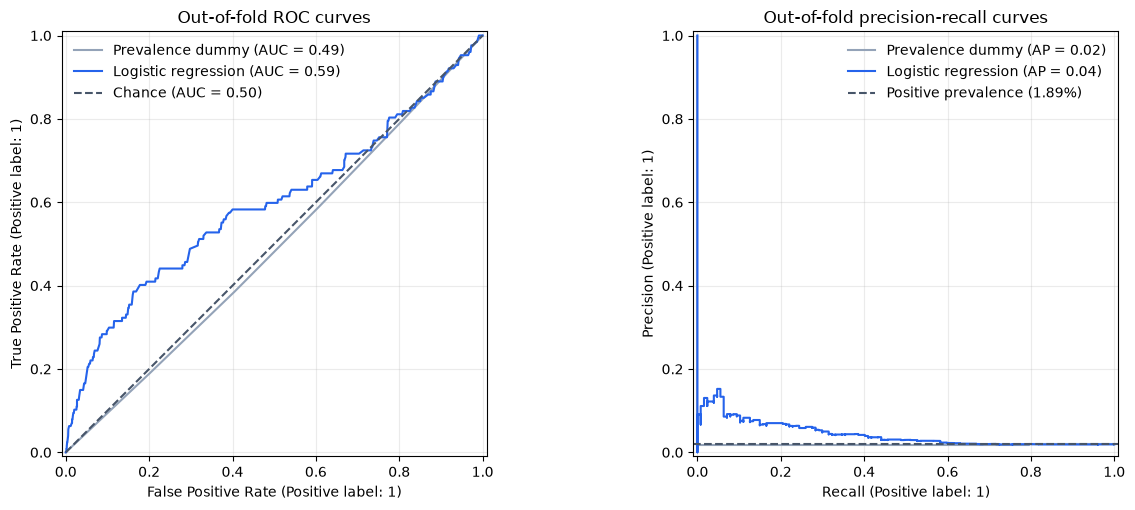

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for model_name in estimators:
    probability_column = f"{model_name}_probability"
    RocCurveDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[0],
    )
    PrecisionRecallDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[1],
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="#475569", label="Chance (AUC = 0.50)")
axes[0].set_title("Out-of-fold ROC curves")
axes[0].legend(frameon=False)

positive_prevalence = train["target"].mean()
axes[1].axhline(
    positive_prevalence,
    linestyle="--",
    color="#475569",
    label=f"Positive prevalence ({positive_prevalence:.2%})",
)
axes[1].set_title("Out-of-fold precision-recall curves")
axes[1].legend(frameon=False)

for axis in axes:
    axis.grid(alpha=0.25)

fig.tight_layout()
finish_figure(fig, 'baseline_roc_pr')


### 5. Choose an exploratory cutoff

A cutoff turns a probability into a flag. At 0.50, both models leave every image unflagged. Their scores are mostly small because malignant images are rare.

For the logistic model, we also try its distinct probabilities as candidate cutoffs and choose the one with the highest balanced accuracy. This averages recall and specificity, the fraction of benign images left unflagged, giving both classes equal weight. The dummy stays at 0.50 because its constant score provides no useful within-fold ranking.

The same OOF labels choose and assess the logistic cutoff, so its result is exploratory. It has not been checked on an independent final test.


In [6]:

def select_balanced_accuracy_threshold(y_true, probabilities):
    cutoff = exploratory_cutoff(y_true, probabilities)
    return cutoff, float(balanced_accuracy_score(y_true, np.asarray(probabilities) >= cutoff))
y_true = oof_predictions["target"].to_numpy()
logistic_probabilities = oof_predictions["logistic_probability"].to_numpy()
logistic_threshold, logistic_balanced_accuracy = select_balanced_accuracy_threshold(
    y_true,
    logistic_probabilities,
)

default_threshold_rows = []
for model_name in estimators:
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        probabilities >= 0.50,
        labels=[0, 1],
    ).ravel()
    default_threshold_rows.append(
        {"Model": MODEL_LABELS[model_name], "Threshold": 0.50, "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    )

print("Default 0.50 threshold:")
display(pd.DataFrame(default_threshold_rows).set_index("Model"))
print(f"Selected logistic threshold: {logistic_threshold:.6f}")
print(f"Balanced accuracy at the selected threshold: {logistic_balanced_accuracy:.4f}")


Default 0.50 threshold:


,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,6579,0,127,0
Logistic regression,0.5,6579,0,127,0


Selected logistic threshold: 0.027186
Balanced accuracy at the selected threshold: 0.6119


### 6. Read the confusion matrices

Each matrix shows the decisions made at the cutoff printed above it. Rows are the actual class and columns are the predicted class. TN is a benign image left unflagged; FP is a benign image flagged by mistake. FN is a missed malignant image; TP is a malignant image found.

The percentages add to 100% within each row: the top row describes benign images and the bottom row describes malignant images. Compare TP with FN to see how many malignant cases are found or missed, then check FP to see the false-alarm cost. Darker blue represents more images, but each panel has its own colour scale, so compare the printed numbers across models.

This figure makes the cutoff trade-off concrete. The logistic model finds 51 of 127 malignant images (40.2%) and wrongly flags 1,170 of 6,579 benign images (17.8%). Only 4.2% of its flagged images are malignant.


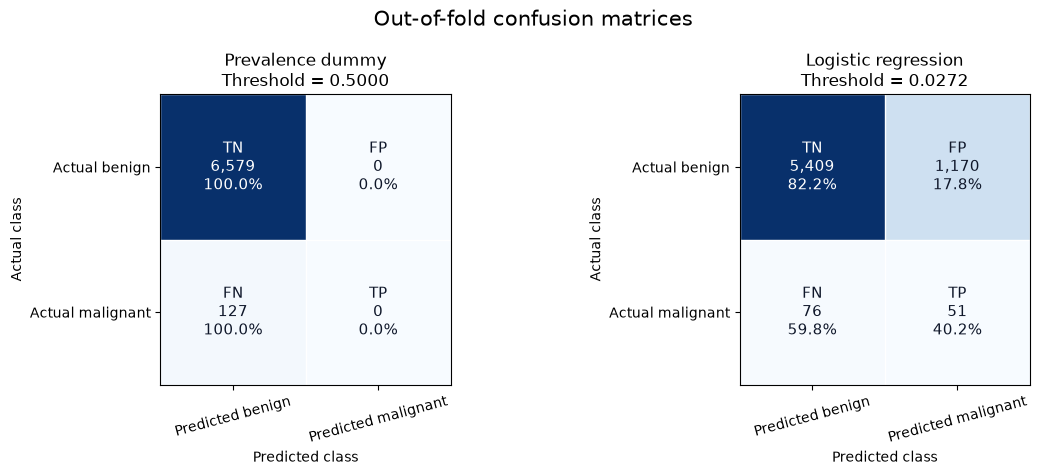

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,6579,100.0000,0,0.0000,127,100.0000,0,0.0000,0.0000
Logistic regression,0.0272,5409,82.2161,1170,17.7839,76,59.8425,51,40.1575,4.1769


In [7]:
matrix_settings = {
    "dummy": 0.50,
    "logistic": logistic_threshold,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
confusion_rows = []

for axis, model_name in zip(axes, estimators):
    threshold = matrix_settings[model_name]
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    predicted_labels = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(y_true, predicted_labels, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()

    row_percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100
    annotations = np.array(
        [
            [
                f"TN\n{tn:,}\n{row_percentages[0, 0]:.1f}%",
                f"FP\n{fp:,}\n{row_percentages[0, 1]:.1f}%",
            ],
            [
                f"FN\n{fn:,}\n{row_percentages[1, 0]:.1f}%",
                f"TP\n{tp:,}\n{row_percentages[1, 1]:.1f}%",
            ],
        ]
    )
    axis.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            text_color = "white" if matrix[row, column] > matrix.max() / 2 else "#0F172A"
            axis.text(
                column,
                row,
                annotations[row, column],
                ha="center",
                va="center",
                color=text_color,
                fontsize=11,
            )
    axis.set_xticks([0, 1], labels=["Predicted benign", "Predicted malignant"])
    axis.set_yticks([0, 1], labels=["Actual benign", "Actual malignant"])
    axis.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    axis.grid(which="minor", color="white", linestyle="-", linewidth=1)
    axis.tick_params(which="minor", bottom=False, left=False)
    axis.set_title(f"{MODEL_LABELS[model_name]}\nThreshold = {threshold:.4f}")
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=15)
    axis.tick_params(axis="y", rotation=0)

    confusion_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "TN": tn,
            "TN % of actual benign": row_percentages[0, 0],
            "FP": fp,
            "FP % of actual benign": row_percentages[0, 1],
            "FN": fn,
            "FN % of actual malignant": row_percentages[1, 0],
            "TP": tp,
            "TP % of actual malignant": row_percentages[1, 1],
            "Precision among predicted malignant (%)": (
                tp / (tp + fp) * 100 if (tp + fp) else 0.0
            ),
        }
    )

fig.suptitle("Out-of-fold confusion matrices", fontsize=15)
fig.tight_layout()
finish_figure(fig, 'baseline_exploratory_confusions')

confusion_results = pd.DataFrame(confusion_rows).set_index("Model")
confusion_results.round(
    {
        "Threshold": 4,
        "TN % of actual benign": 1,
        "FP % of actual benign": 1,
        "FN % of actual malignant": 1,
        "TP % of actual malignant": 1,
        "Precision among predicted malignant (%)": 1,
    }
)

display(confusion_results.round(4))


## Limitations

This is a short development comparison of two fixed models. It does not establish the best metadata model or provide uncertainty intervals for their difference. The same patient folds have also guided the wider model comparison, so later model choices based on these scores may look optimistic.

The logistic cutoff is selected and assessed using the same OOF labels. Its confusion matrix illustrates a possible trade-off; it cannot establish how well that cutoff will work on new patients. The low malignant-image rate also means a model can make few overall errors while missing many malignant cases.

Age, sex and site do not describe lesion appearance. These results do not establish calibrated risks, causation, clinical safety or performance on the reserved test set. See notebook 08 for the later uncertainty and cutoff checks.


## Summary

Logistic regression improves AP from 0.0184 to 0.0430 and pooled ROC-AUC from 0.4877 to 0.5943. The dummy has ROC-AUC 0.5 within every fold; its pooled value shifts slightly because training-fold prevalences differ.

On the primary mean-fold measure, AP is 0.0189 for the dummy and 0.0567 for logistic regression. Keep the dummy as a reference and logistic regression as a simple comparison. Its exploratory cutoff finds some malignant images with many false alarms; this is not a clinical rule.

Next, [05_metadata_models.ipynb](05_metadata_models.ipynb) compares more flexible models, [06_metadata_neural_network.ipynb](06_metadata_neural_network.ipynb) tests a small network, and [08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) checks uncertainty and training-selected cutoffs.


## Additional deduplicated-workflow diagnostics

The complete original section sequence above is retained as the template. The following clearly labelled additions document clean artifact verification, training support and explanatory diagnostics that were not figures in the original. They remain secondary development evidence and do not select another model or cutoff.

In [8]:

import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))


,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


In [9]:
metrics = metric_table(frame, scores, ['dummy', 'categorical_logistic'])

### Added diagnostic: 7. Inspect saved logistic associations and state the limits

Coefficients describe regularised associations among encoded categories; they are neither causes nor stable patient risk factors. A category absent from one training fold has no coefficient in that fit. Error bars below show variability across available saved fits, not sampling confidence intervals. This remains a development comparison before image information.

,mean,std,count
encoded_feature,,,
categorical__sex_female,-1.1640,0.0555,5
categorical__age_approx_35,-0.9953,0.2193,5
categorical__sex_male,-0.9412,0.1134,5
categorical__age_approx_40,-0.8113,0.2946,5
categorical__anatom_site_general_challenge_palms/soles,-0.8039,0.0365,5
categorical__age_approx_25,-0.7276,0.1442,5
categorical__anatom_site_general_challenge_lower extremity,-0.7093,0.1185,5
categorical__anatom_site_general_challenge_torso,-0.6823,0.0855,5
categorical__age_approx_45,-0.6294,0.1410,5


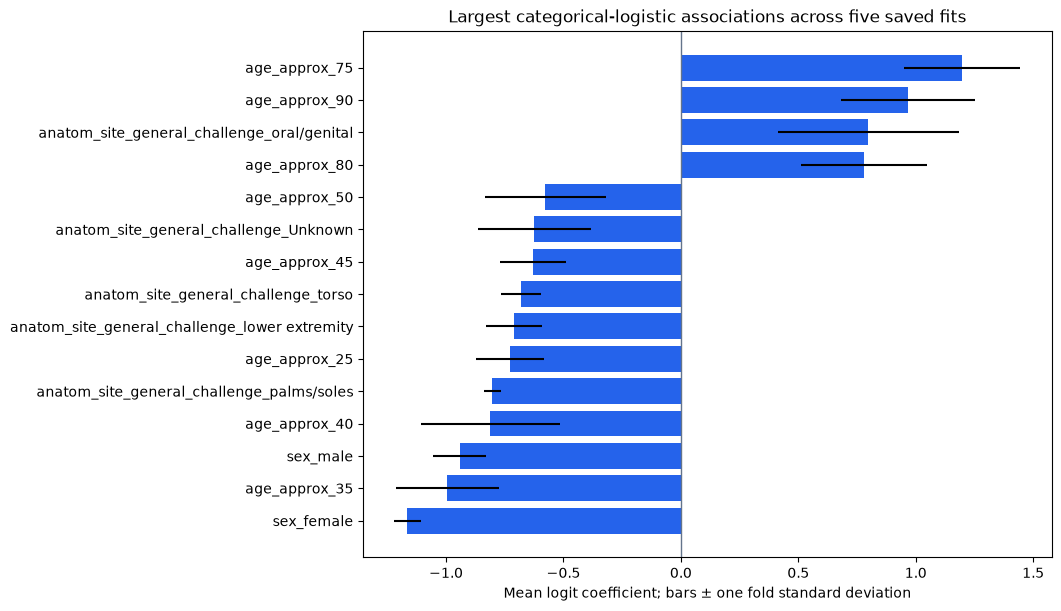

Mean-fold AP: dummy **0.0190**, logistic **0.0567**. The fixed-cutoff and OOF-selected matrices describe different decision scenarios; only the latter reuses scoring labels to choose a cutoff. No reserved-test conclusion follows.

In [10]:
coefficients, _, _ = estimator_diagnostics(meta)
summary = coefficients.groupby("encoded_feature").logit_coefficient.agg(["mean", "std", "count"])
selected = summary.reindex(summary["mean"].abs().nlargest(15).index).sort_values("mean")
display(selected.round(4))
fig, ax = plt.subplots(figsize=(10.5, 6), layout="constrained")
ax.barh(selected.index.str.replace("categorical__", "", regex=False), selected["mean"], xerr=selected["std"].fillna(0), color="#2563eb")
ax.axvline(0, color="#64748b", linewidth=1)
ax.set(title="Largest categorical-logistic associations across five saved fits", xlabel="Mean logit coefficient; bars ± one fold standard deviation")
finish_figure(fig, "baseline_logistic_coefficients")
gain = metrics.loc[metrics.scope.eq("mean_fold")].set_index("model").average_precision
display(Markdown(f"Mean-fold AP: dummy **{gain['dummy']:.4f}**, logistic **{gain['categorical_logistic']:.4f}**. The fixed-cutoff and OOF-selected matrices describe different decision scenarios; only the latter reuses scoring labels to choose a cutoff. No reserved-test conclusion follows."))